# Play with LyaCoLoRe raw deltas (no noise)

- Read Lyman alpha deltas computed directly from the LyaCoLoRe outputs, without noise or quasar continua
- Rebin the deltas and write them to file

The process of rebinning all the deltas is quite slow, so here we only do a test. The actual script to do this for the entire simulation is under the `scripts/` folder.

In [1]:
import os
import numpy as np
#import pyccl as ccl
import healpy as hp
import matplotlib.pyplot as plt
#import libconf
#from scipy.integrate import simps
from astropy.io import fits

In [2]:
# folder with the raw deltas
delta_dir='/global/cfs/cdirs/desicollab/users/lauracdp/cmb_lensing_box/mock_analysis/raw_master/deltas_lya/Delta'
# healpixelization used for the deltas
nside=16
# hard-coded constants (great coding here)
lya_rf=1215.67

### Look at a particular healpixel

In [3]:
# chose a random healpixel
fname=delta_dir+'/delta-3044.fits.gz'
hdus = fits.open(fname)

0 zq=2.20 , lrmin=1124.60, lrmax=1205.07
1 zq=2.20 , lrmin=1126.51, lrmax=1204.86
2 zq=2.18 , lrmin=1131.20, lrmax=1204.85


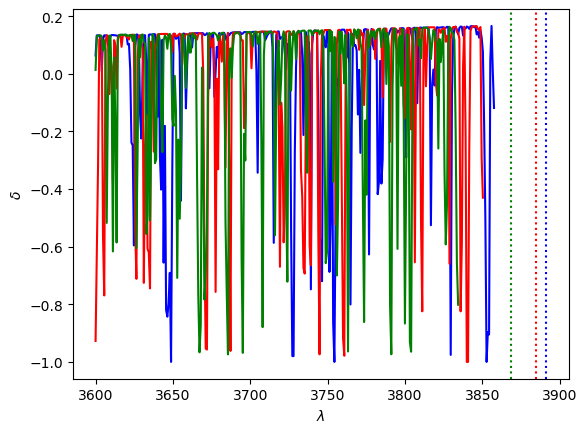

In [4]:
# pick a couple of quasars from this healpixel and plot them
iq1=1000
Nq=3
colors=['blue', 'red', 'green']
for iq in range(Nq):
    # read relevant metadata
    header = hdus[iq1+iq].header
    zq = header['Z']
    ra = header['RA']
    dec = header['DEC']
    # read vector values
    data = hdus[iq1+iq].data
    loglambda = data['LOGLAM']
    delta = data['DELTA']
    weight = data['WEIGHT']
    print(iq, 'zq={:.2f} , lrmin={:.2f}, lrmax={:.2f}'.format(zq, 10**np.min(loglambda)/(1+zq), 10**np.max(loglambda)/(1+zq)))
    plt.plot(10**loglambda, delta, color=colors[iq])
    plt.axvline(x=lya_rf*(1+zq), ls=':', color=colors[iq])
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\delta$');

In [5]:
# read relevant metadata for one skewer
iq=1600
header = hdus[iq].header
zq = header['Z']
ra = header['RA']
dec = header['DEC']
# read vector values
data = hdus[iq].data
loglambda = data['LOGLAM']
delta = data['DELTA']
weight = data['WEIGHT']
print(zq, 10**np.min(loglambda)/(1+zq), 10**np.max(loglambda)/(1+zq))

3.28822994232178 1040.056167693568 1204.9726972435435


In [6]:
zmin=2.5
zmax=3.0
lmin=lya_rf*(1+zmin)
lmax=lya_rf*(1+zmax)
print(zmin, zmax, lmin, lmax)

2.5 3.0 4254.845 4862.68


In [7]:
lam=10**loglambda
mask=(lam>lmin) & (lam<lmax)
sum_w=np.sum(weight[mask])
mean_z=0
mean_delta=0
if sum_w>0:
    mean_z=np.sum(weight*(lam/lya_rf-1))/sum_w
    mean_delta=np.sum(weight*delta)/sum_w

In [8]:
# define range such that no pixel falls through the cracks
lmin=3599.9
lmax=5600
dlam=100
Nlam=int((lmax-lmin)/dlam)
print('Number of z bins =', Nlam)

Number of z bins = 20


In [9]:
sum_w=np.zeros(Nlam)
mean_z=np.zeros(Nlam)
mean_delta=np.zeros(Nlam)
for il in range(Nlam):
    ilmin=lmin+il*dlam
    ilmax=ilmin+dlam
    mask=(lam>ilmin) & (lam<ilmax)
    sum_w[il]=np.sum(weight[mask])
    if sum_w[il]>0:
        mean_z[il]=np.sum(weight[mask]*(lam[mask]/lya_rf-1))/sum_w[il]
        mean_delta[il]=np.sum(weight[mask]*delta[mask])/sum_w[il]

In [10]:
def rebin_deltas(hdus, iq, lmin, lmax, dlam):
    info ={}
    header = hdus[iq].header
    info['zq'] = header['Z']
    info['ra_rad'] = header['RA']
    info['dec_rad'] = header['DEC']
    info['targetid'] = header['THING_ID']
    # read forest before rebinning
    data = hdus[iq].data
    lam = np.power(10.0, data['LOGLAM'])
    delta = data['DELTA']
    weight = data['WEIGHT']
    # rebin quantities
    Nlam=int((lmax-lmin)/dlam)
    info['sum_w']=np.zeros(Nlam)
    info['mean_z']=np.zeros(Nlam)
    info['mean_delta']=np.zeros(Nlam)
    for il in range(Nlam):
        ilmin=lmin+il*dlam
        ilmax=ilmin+dlam
        mask=(lam>=ilmin) & (lam<ilmax)
        info['sum_w'][il]=np.sum(weight[mask])
        if info['sum_w'][il]>0:
            info['mean_z'][il]=np.sum(weight[mask]*(lam[mask]/lya_rf-1))/info['sum_w'][il]
            info['mean_delta'][il]=np.sum(weight[mask]*delta[mask])/info['sum_w'][il]
    return info

In [11]:
def rebin_deltas_in_healpix(fname, lmin, lmax, dlam):
    # chose a random healpixel
    hdus = fits.open(fname)
    Nq = len(hdus)
    dataset = []
    for iq in range(1, Nq):
        if (iq%200==0):
            print('read quasar', iq)
        dataset.append(rebin_deltas(hdus, iq, lmin, lmax, dlam))
    return dataset

In [12]:
dataset = rebin_deltas_in_healpix(fname, lmin, lmax, dlam)

read quasar 200
read quasar 400
read quasar 600
read quasar 800
read quasar 1000
read quasar 1200
read quasar 1400
read quasar 1600
read quasar 1800


### Write rebinned deltas

In [13]:
dataset[0]

{'zq': 2.18479609489441,
 'ra_rad': 5.01871162792,
 'dec_rad': -1.31895796042097,
 'targetid': 160182849,
 'sum_w': array([1775.86722277, 1602.80592619,  573.22852796,    0.        ,
           0.        ,    0.        ,    0.        ,    0.        ,
           0.        ,    0.        ,    0.        ,    0.        ,
           0.        ,    0.        ,    0.        ,    0.        ,
           0.        ,    0.        ,    0.        ,    0.        ]),
 'mean_z': array([2.00142956, 2.08368706, 2.14121025, 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ]),
 'mean_delta': array([-0.01733392, -0.0006432 ,  0.03097163,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.  

In [14]:
zq = np.array([data['zq'] for data in dataset])
ra_rad = np.array([data['ra_rad'] for data in dataset])
dec_rad = np.array([data['dec_rad'] for data in dataset])
targetid = np.array([data['targetid'] for data in dataset])

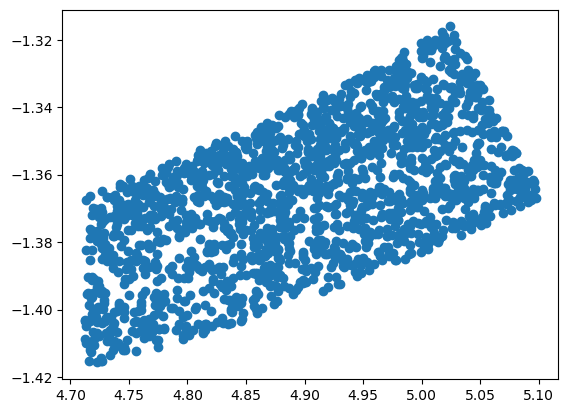

In [15]:
plt.scatter(ra_rad, dec_rad)

In [16]:
Nq=len(dataset)
Nlam=len(dataset[0]['sum_w'])
sum_w=np.zeros([Nq, Nlam])
mean_z=np.zeros([Nq, Nlam])
mean_delta=np.zeros([Nq, Nlam])
for iq in range(Nq):
    sum_w[iq] = dataset[iq]['sum_w']
    mean_z[iq] = dataset[iq]['mean_z']
    mean_delta[iq] = dataset[iq]['mean_delta']

In [17]:
def write_rebinned_deltas(fname, dataset):
    zq = np.array([data['zq'] for data in dataset])
    ra_rad = np.array([data['ra_rad'] for data in dataset])
    dec_rad = np.array([data['dec_rad'] for data in dataset])
    targetid = np.array([data['targetid'] for data in dataset])
    Nq=len(dataset)
    Nlam=len(dataset[0]['sum_w'])
    sum_w=np.zeros([Nq, Nlam])
    mean_z=np.zeros([Nq, Nlam])
    mean_delta=np.zeros([Nq, Nlam])
    for iq in range(Nq):
        sum_w[iq] = dataset[iq]['sum_w']
        mean_z[iq] = dataset[iq]['mean_z']
        mean_delta[iq] = dataset[iq]['mean_delta']
    np.savez(fname, zq=zq, ra_rad=ra_rad, dec_rad=dec_rad, targetid=targetid, 
             sum_w=sum_w, mean_z=mean_z, mean_delta=mean_delta)

In [18]:
write_rebinned_deltas(fname='test.npz', dataset=dataset)